# 내일 태양광 발전량 예측기 — 데이터·학습·평가 노트북

기계학습 프로그래밍 기말 프로젝트 · 201935607 김대현

발전소 위치의 **하루 전 기상 예보**로 다음 날 시간대별 태양광 발전량을 예측하는 모델을 만들고, 브라우저에서 돌아가는 서비스용 파일로 내보낸다.
이 노트북은 README의 `2. 데이터`, `3. 데이터 전처리`, `4. 모델`, `5. 평가 결과`에 실린 표와 그림을 모두 여기서 만든다.

| 절 | 내용 |
|---|---|
| 0 | 실행 환경 |
| 1 | 문제와 정량 목표 |
| 2 | 데이터: 출처·규모·구성 |
| 3 | 전처리: 단계별 전·후 비교, 분할 |
| 4 | 모델: 기준 예측, 베이스라인(선형회귀), 제안 모델(그래디언트 부스팅, GRU) 학습 |
| 5 | 평가: 시험 구간 비교표, 학습 곡선, 오류 분석 |
| 6 | 서비스용 내보내기: ONNX 변환과 일치 검증 |

**실행 방법**: `pip install -r requirements.txt` 후 위에서부터 차례로 실행한다. 원자료(`data/raw`)가 저장소에 들어 있어 내려받기 없이 실행되고, 파일이 없을 때만 새로 받는다. M1 Pro(CPU)에서 전체 실행에 10분쯤 걸린다.

## 0. 실행 환경

In [1]:
import json, platform, sys, time, warnings
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import build_dataset, download_kospo, download_weather
import modeling as M
import plots as P
from export_onnx import check_parity, hgb_to_onnx

warnings.filterwarnings("ignore")
SEED = 42
M.set_seed(SEED)
torch.set_num_threads(4)
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
font = P.set_style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)

print(f"Python {platform.python_version()} · {platform.platform()}")
print(f"numpy {np.__version__} · pandas {pd.__version__} · scikit-learn {sklearn.__version__} · torch {torch.__version__}")
print(f"seed {SEED} · 그림 글꼴 {font}")

Python 3.13.7 · macOS-27.0.1-arm64-arm-64bit-Mach-O
numpy 2.5.4 · pandas 3.1.1 · scikit-learn 1.9.1 · torch 2.15.0
seed 42 · 그림 글꼴 Apple SD Gothic Neo


## 1. 문제와 정량 목표

- **누가**: 소규모 태양광 발전사업자와, 이들을 모아 전력시장에 참여하는 전력중개사업자
- **무엇을**: 발전소 위치와 설비용량만으로 다음 날 시간대별 발전량(kWh)을 예측
- **언제**: 발전 하루 전, 예측값을 제출하기 전
- **왜**: 재생에너지 발전량 예측제도는 예측 오차율이 기준 이내인 시간대에만 정산금을 준다. 태양광은 2025년 6월부터 기준선이 8%에서 6%로 강화됐다.

**평가 지표**: 예측과 실제의 차이를 설비용량으로 나눈 값의 평균(NMAE, %). 제도의 예측오차율과 같은 정의다.

**정량 목표**

1. 발전소 묶음(집합 자원) 오차율 ≤ 6% — 제도가 정산하는 단위. 이용률 10% 이상 시간대 기준
2. 개별 발전소 평균 오차율(NMAE) ≤ 6% — 더 어려운 도전 목표

아래 모든 판단(모델·설정 선택)은 검증 구간으로만 하고, 시험 구간은 5절에서 한 번만 쓴다.

## 2. 데이터

| 구분 | 출처 | 라이선스 | 내용 |
|---|---|---|---|
| 발전실적 | [공공데이터포털](https://www.data.go.kr), 한국남부발전(주) 발전소별 태양광 발전실적 | 이용허락범위 제한 없음 | 발전소·호기별 1시간 단위 발전량(kWh) |
| 설비용량 | 공공데이터포털, 한국남부발전(주) 에너지원별 신재생에너지 발전설비 현황 | 이용허락범위 제한 없음 | 발전소별 공식 설비용량(MW), 준공 연도 |
| 날씨 예보 | [Open-Meteo](https://open-meteo.com) Previous Runs API | CC BY 4.0 | 24시간 전에 발표된 예보(일사량·구름 양·기온 등), 기상 모델 3종 |

### 2-1. 원자료 확인 (없으면 내려받기)

In [2]:
RAW = ROOT / "data" / "raw"
plants_all = pd.read_csv(ROOT / "data" / "plants.csv", dtype={"data_id": str})
used = plants_all[plants_all["use"] == 1]

if not (RAW / "kospo" / "manifest.json").exists():
    download_kospo.main()            # 공공데이터포털에서 발전실적 CSV 40건
need = {build_dataset.site_key(a, b) for a, b in used[["lat", "lon"]].drop_duplicates().itertuples(index=False)}
have = {p.name.replace("_d1.csv.gz", "") for p in (RAW / "weather").glob("*_d1.csv.gz")}
if need - have:
    download_weather.main()          # Open-Meteo 하루 전 예보 이력(위치 18곳, 약 30분)

manifest = pd.DataFrame(json.loads((RAW / "kospo" / "manifest.json").read_text(encoding="utf-8")))
files = manifest[manifest["id"].isin(used["data_id"])]
print(f"발전실적 파일 {len(files)}개 · 일 단위 {files['rows'].sum():,}행 (하루 한 줄에 시간 열 24개 → 시간 단위 {files['rows'].sum() * 24:,}건)")
print(f"파일별 기간: 가장 이른 시작 {files['first_date'].min()} · 가장 늦은 끝 {files['last_date'].max()}")
print(f"날씨 파일 {len(have & need)}개 위치 · 2024-01-01 ~ 2026-02-28 · 위치마다 1시간 단위 18,960행")
display(files[["id", "title", "rows", "first_date", "last_date", "license"]].head(5))

발전실적 파일 33개 · 일 단위 134,140행 (하루 한 줄에 시간 열 24개 → 시간 단위 3,219,360건)
파일별 기간: 가장 이른 시작 2013-01-01 · 가장 늦은 끝 2026-06-30
날씨 파일 18개 위치 · 2024-01-01 ~ 2026-02-28 · 위치마다 1시간 단위 18,960행


,id,title,rows,first_date,last_date,license
0,15043384,한국남부발전(주)_남제주소내 태양광발전실적_20260228,4807,2013-01-01,2026-02-28,이용허락범위 제한 없음
1,15043385,한국남부발전(주)_부산복합자재창고 태양광발전실적_20260228,4807,2013-01-01,2026-02-28,이용허락범위 제한 없음
2,15043386,한국남부발전(주)_부산본부 태양광발전실적_20260228,7425,2013-01-01,2026-02-28,이용허락범위 제한 없음
3,15043387,한국남부발전(주)_부산수처리장 태양광발전실적_20260228,2981,2018-01-01,2026-02-28,이용허락범위 제한 없음
4,15043388,한국남부발전(주)_부산신항 태양광발전실적_20260228,4807,2013-01-01,2026-02-28,이용허락범위 제한 없음


### 2-2. 발전소 구성

목록에 올린 발전소·호기 47개 중 42개 사용, 5개는 아래 이유로 제외


,name,note
0,행원소수력,2024년 이후 발전량 0인 날이 74%라 제외
1,감우리,소재지를 공개 자료로 특정하지 못해 제외
2,세화리,제주에 세화리가 두 곳(구좌읍·표선면)이라 소재지를 특정하지 못해 제외
3,익산 다송리,파일에 누적 계량값과 빈 날짜 행이 섞여 있어 제외
4,부산철도 2호기,2025년 1월 이후 자료만 있고 소재지 미상이라 제외


,발전소_호기,위치,설비용량_합계_kW
region,,,
육지,35,11,"27,639.900"
제주,7,7,"5,693.000"


capacity_kw,100kW 이하,100~500kW,500kW~1MW,1MW 초과
발전소·호기 수,5,10,20,7


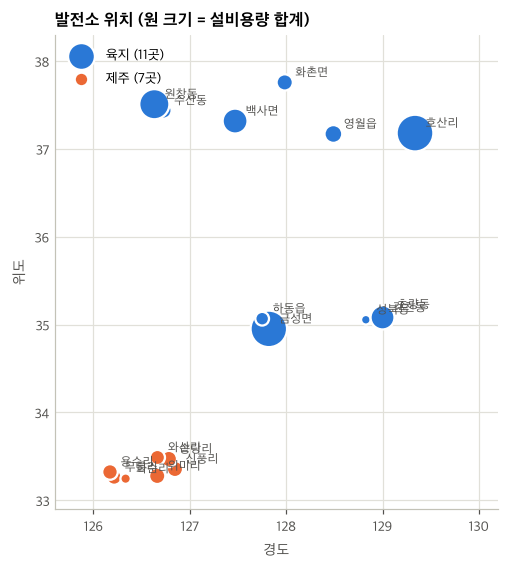

In [3]:
print(f"목록에 올린 발전소·호기 {len(plants_all)}개 중 {len(used)}개 사용, {len(plants_all) - len(used)}개는 아래 이유로 제외")
display(plants_all.loc[plants_all["use"] == 0, ["name", "note"]].reset_index(drop=True))

by_region = used.groupby("region").agg(발전소_호기=("series_id", "count"), 위치=("area", "nunique"), 설비용량_합계_kW=("capacity_kw", "sum"))
display(by_region)
size = pd.cut(used["capacity_kw"], [0, 100, 500, 1000, 3000], labels=["100kW 이하", "100~500kW", "500kW~1MW", "1MW 초과"])
display(size.value_counts().sort_index().rename("발전소·호기 수").to_frame().T)

sites = used.groupby(["area", "region", "lat", "lon"], as_index=False).agg(kw=("capacity_kw", "sum"), n=("series_id", "count"))
fig, ax = plt.subplots(figsize=(5.2, 5.6))
for region, color in (("육지", P.BLUE), ("제주", P.ORANGE)):
    s = sites[sites["region"] == region]
    ax.scatter(s["lon"], s["lat"], s=30 + s["kw"] / 12, color=color, edgecolor="white", linewidth=1.5, label=f"{region} ({len(s)}곳)", zorder=3)
for row in sites.itertuples():
    ax.annotate(row.area.split()[-1], (row.lon, row.lat), xytext=(7, 4), textcoords="offset points", fontsize=8, color=P.INK2)
ax.set(xlabel="경도", ylabel="위도", title="발전소 위치 (원 크기 = 설비용량 합계)", xlim=(125.6, 130.2), ylim=(32.9, 38.3))
ax.grid(True, axis="both")
ax.legend(loc="upper left")
P.save(fig, FIG / "01_sites.png")

### 2-3. 원자료 모양

In [4]:
sample = manifest[manifest["id"] == "15043388"].iloc[0]    # 부산신항
raw_gen = pd.read_csv(RAW / "kospo" / sample["file"], encoding=sample["encoding"])
print("발전실적 원자료(부산신항):", raw_gen.shape, "— 하루 한 줄, 1~24 열이 시간대별 발전량")
display(raw_gen.iloc[[0, 4000], :18])

raw_weather = pd.read_csv(RAW / "weather" / "35.055_128.827_d1.csv.gz")
print("날씨 원자료(부산신항 위치):", raw_weather.shape, "— 한 시간 한 줄, 기상 모델 3종 × 변수 9개")
display(raw_weather.iloc[[12000, 12001], [2, 3, 6, 7, 12, 21]])
print("헤더 형식:", manifest.loc[manifest["id"].isin(used["data_id"]), "header"].str[:40].nunique(), "가지 (시간 열 이름이 '1'..'24' 인 파일과 '0-1시 발전량(kWh)' 인 파일이 섞여 있음)")

발전실적 원자료(부산신항): (4807, 32) — 하루 한 줄, 1~24 열이 시간대별 발전량


,년월일,호기,총량(kw),평균(kw),최대(kw),최소(kw),최대(시간별_kw),최소(시간별_kw),1,2,3,4,5,6,7,8,9,10
0,2013-01-01,1,220.044,9.000,39.168,0,39.168,4.512,0,0,0,0,0,0.000,0.000,0.000,6.048,15.828
4000,2023-12-15,1,0.000,0.000,0.000,0,0.000,0.000,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000


날씨 원자료(부산신항 위치): (18960, 30) — 한 시간 한 줄, 기상 모델 3종 × 변수 9개


,time,shortwave_radiation_previous_day1_jma_seamless,cloud_cover_previous_day1_jma_seamless,temperature_2m_previous_day1_jma_seamless,shortwave_radiation_previous_day1_ecmwf_ifs025,shortwave_radiation_previous_day1_icon_seamless
12000,2025-05-15T00:00,0.000,100,14.500,0.000,0.000
12001,2025-05-15T01:00,0.000,100,14.400,0.000,0.000


헤더 형식: 3 가지 (시간 열 이름이 '1'..'24' 인 파일과 '0-1시 발전량(kWh)' 인 파일이 섞여 있음)


## 3. 전처리

`src/build_dataset.py`가 아래 순서로 처리한다. 각 단계의 전·후 건수는 실행 결과에 그대로 찍힌다.

| 단계 | 기법 | 이유 |
|---|---|---|
| ① 형식 통일 | 넓은 표 → 긴 표, 시간 열 이름 2종 통일, 중복 날짜 제거 | 파일마다 열 구성이 다르고 하루가 한 줄이라 날씨와 맞붙일 수 없음 |
| ②③ 오류 제거 | 결측·음수 제거, 실적이 공식 설비용량의 105%를 넘는 발전소 제외 | 설비용량으로 나누는 지표라 용량 정보가 틀리면 모든 값이 틀어짐 |
| ④ 정지일 제외 | 하루 발전량이 평소(중앙값)의 2% 미만인 날 제거 | 고장·정비로 멈춘 날은 날씨로 설명되지 않음 |
| ⑤ 날씨 결합·파생 변수 | 태양 고도·방위각, 대기권 밖 일사량, 맑음 지수, 기상 모델 간 평균·편차 | 같은 일사량이라도 계절·시각에 따라 의미가 다름 |
| ⑥ 밤 시간 제외 | 태양 고도 ≤ 0°인 시간 제거 | 발전량이 0으로 정해져 있어 예측 대상이 아님 |
| ⑧ 정규화 | 발전량 ÷ 설비용량 (설비이용률) | 40kW~2.6MW인 발전소를 한 모델로 학습 |
| ⑨ 분할 | 시간 순 분할 + 위치 4곳 통째로 분리(seed 42) | 미래 기간과 처음 보는 발전소에서의 성능을 따로 확인 |

### 3-1. 실행과 단계별 건수

In [5]:
build_dataset.main()
report = json.loads((ROOT / "data" / "processed" / "prep_report.json").read_text(encoding="utf-8"))
FEATURES = report["features"]
df = pd.read_parquet(ROOT / "data" / "processed" / "hourly.parquet").sort_values(["series_id", "date", "hour"]).reset_index(drop=True)
steps = pd.DataFrame(report["steps"]).rename(columns={"step": "단계", "before": "전(행)", "after": "후(행)", "note": "비고"})
steps["줄어든 행"] = steps["전(행)"] - steps["후(행)"]
display(steps[["단계", "전(행)", "후(행)", "줄어든 행", "비고"]])

발전실적: 발전소·호기 42개, 시간 단위 728,784행
  ① 같은 날짜가 두 번 나온 행 제거                 728,784 →   728,784  
  ② 결측·음수 발전량 제거                       728,784 →   728,784  
  ③ 설비용량 불일치 발전소 제외                    728,784 →   694,080  2곳: 신인천전망대, 신인천 1_2단계 주차장


  ④ 정지일(하루 발전량 ≈ 0) 제외                 694,080 →   684,408  발전소·일 403건


  ⑤ 날씨 예보가 비어 있는 시간 제외                 684,408 →   684,369  
  ⑥ 밤 시간(태양 고도 ≤ 0°) 제외                684,369 →   343,306  밤 시간 발전량 비중 0.0701%
  ⑦ 남은 날 300일 미만 발전소 제외                343,306 →   343,306  0곳



최종: 발전소·호기 40개, 위치 18곳, 343,306행, 특성 40개
분할별 행 수: {'train': 109116, 'test': 107584, 'unused': 50079, 'val': 40306, 'test_new_site': 36221}
처음 보는 발전소: {'37.757_127.985': ['화촌주민참여형'], '34.951_127.820': ['하동본부 1호기', '하동본부 2호기', '하동본부 3호기', '하동본부 4호기', '하동본부 5호기', '하동본부 6호기'], '37.317_127.470': ['이천D(백사면B)', '이천시 백사면A'], '33.487_126.664': ['와산리']}


,단계,전(행),후(행),줄어든 행,비고
0,① 같은 날짜가 두 번 나온 행 제거,728784,728784,0,
1,② 결측·음수 발전량 제거,728784,728784,0,
2,③ 설비용량 불일치 발전소 제외,728784,694080,34704,"2곳: 신인천전망대, 신인천 1_2단계 주차장"
3,④ 정지일(하루 발전량 ≈ 0) 제외,694080,684408,9672,발전소·일 403건
4,⑤ 날씨 예보가 비어 있는 시간 제외,684408,684369,39,
5,⑥ 밤 시간(태양 고도 ≤ 0°) 제외,684369,343306,341063,밤 시간 발전량 비중 0.0701%
6,⑦ 남은 날 300일 미만 발전소 제외,343306,343306,0,0곳


### 3-2. 전·후 비교

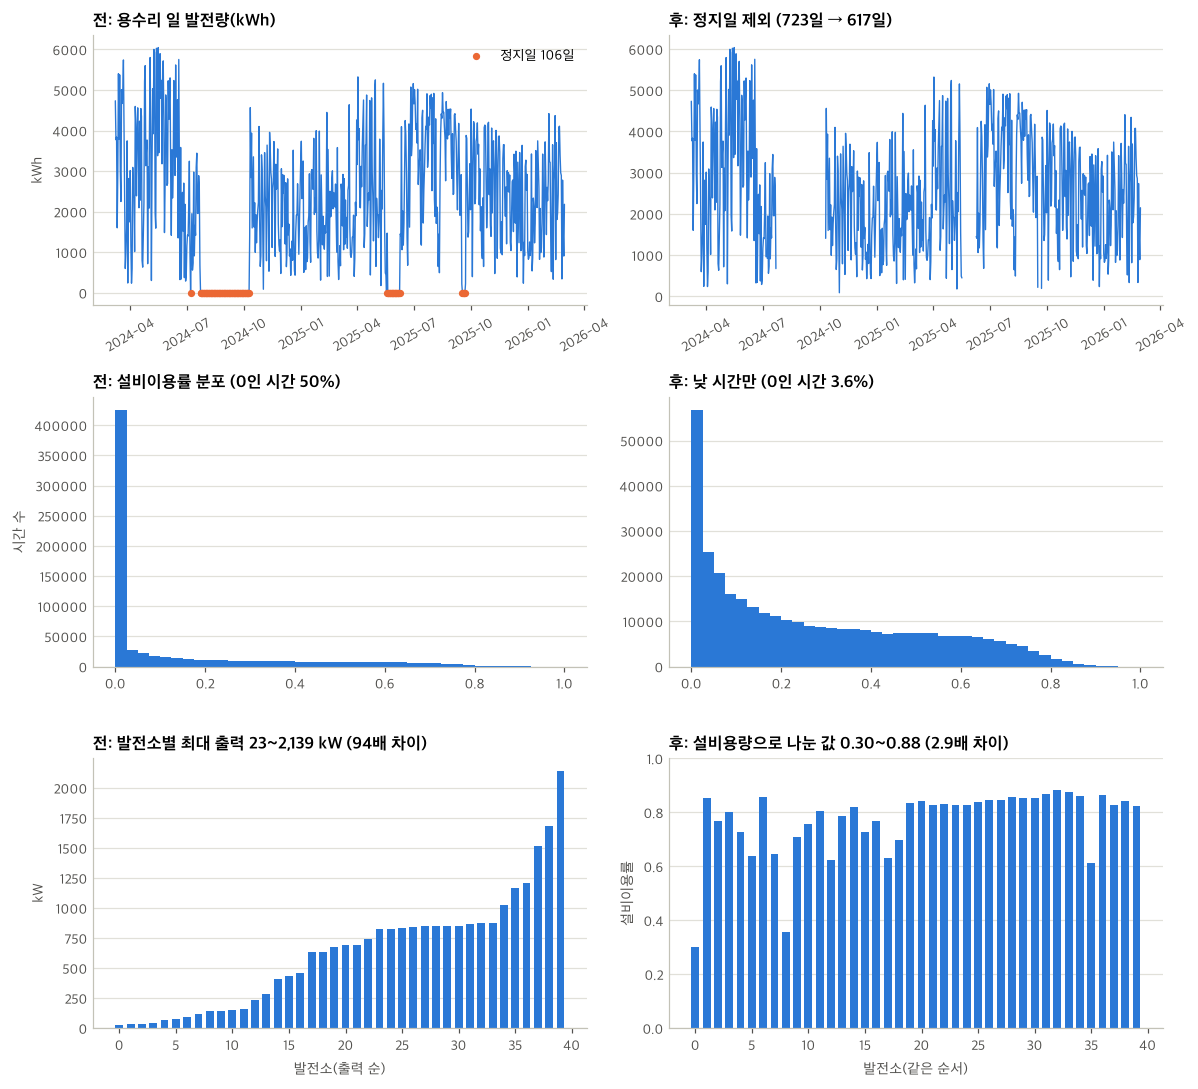

,전,후
표 형태,33개 파일 · 하루 한 줄 · 헤더 2종,표 1개 · 한 시간 한 줄
행 수(시간 단위),"728,784","343,306"
발전량 0인 행 비율,50.2%,3.6%
발전소 간 최대 출력 차이,94배,2.9배
모델 입력 특성,없음,40개


In [6]:
# 정제 전 상태를 다시 만든다(시간 단위로 펴기만 한 표)
used_p = used.assign(site=[build_dataset.site_key(a, b) for a, b in zip(used["lat"], used["lon"])])
man = {m["id"]: m for m in json.loads((RAW / "kospo" / "manifest.json").read_text(encoding="utf-8"))}
before = build_dataset.read_generation(used_p, man).merge(used_p[["series_id", "name", "capacity_kw"]], on="series_id")

fig, axes = plt.subplots(3, 2, figsize=(11, 10))

# (가) 정지일 제외 — 제주 용수리의 일 발전량
one = before[before["name"] == "용수리"].groupby("date")["gen_kwh"].sum()
kept = df[df["name"] == "용수리"].groupby("date")["gen_kwh"].sum()
out_days = one.index.difference(kept.index)
axes[0, 0].plot(one.index, one.values, color=P.BLUE, lw=0.9)
axes[0, 0].scatter(out_days, one.loc[out_days], s=14, color=P.ORANGE, zorder=3, label=f"정지일 {len(out_days)}일")
axes[0, 0].set(title="전: 용수리 일 발전량(kWh)", ylabel="kWh")
axes[0, 0].legend(loc="upper right")
kept_line = kept.reindex(pd.date_range(kept.index.min(), kept.index.max()))   # 빠진 날은 선을 끊는다
axes[0, 1].plot(kept_line.index, kept_line.values, color=P.BLUE, lw=0.9)
axes[0, 1].set(title=f"후: 정지일 제외 ({len(one)}일 → {len(kept)}일)")
for ax in axes[0]:
    ax.tick_params(axis="x", labelrotation=30)

# (나) 밤 시간 제외 — 발전량 0인 시간의 비중
zero_before = (before["gen_kwh"] == 0).mean()
zero_after = (df["gen_kwh"] == 0).mean()
axes[1, 0].hist(before["gen_kwh"] / before["capacity_kw"], bins=40, range=(0, 1), color=P.BLUE)
axes[1, 0].set(title=f"전: 설비이용률 분포 (0인 시간 {zero_before:.0%})", ylabel="시간 수")
axes[1, 1].hist(df["cf"], bins=40, range=(0, 1), color=P.BLUE)
axes[1, 1].set(title=f"후: 낮 시간만 (0인 시간 {zero_after:.1%})")

# (다) 정규화 — 발전소별 시간당 최대 출력
peak_kw = df.groupby("name")["gen_kwh"].quantile(0.995).sort_values()
peak_cf = df.groupby("name")["cf"].quantile(0.995).reindex(peak_kw.index)
axes[2, 0].bar(range(len(peak_kw)), peak_kw.values, color=P.BLUE, width=0.7)
axes[2, 0].set(title=f"전: 발전소별 최대 출력 {peak_kw.min():.0f}~{peak_kw.max():,.0f} kW ({peak_kw.max() / peak_kw.min():.0f}배 차이)", ylabel="kW", xlabel="발전소(출력 순)")
axes[2, 1].bar(range(len(peak_cf)), peak_cf.values, color=P.BLUE, width=0.7)
axes[2, 1].set(title=f"후: 설비용량으로 나눈 값 {peak_cf.min():.2f}~{peak_cf.max():.2f} ({peak_cf.max() / peak_cf.min():.1f}배 차이)", ylabel="설비이용률", xlabel="발전소(같은 순서)", ylim=(0, 1))
fig.tight_layout()
P.save(fig, FIG / "02_preprocessing.png")

summary = pd.DataFrame(
    {
        "전": [f"{len(files)}개 파일 · 하루 한 줄 · 헤더 2종", f"{len(before):,}", f"{zero_before:.1%}", f"{peak_kw.max() / peak_kw.min():.0f}배", "없음"],
        "후": ["표 1개 · 한 시간 한 줄", f"{len(df):,}", f"{zero_after:.1%}", f"{peak_cf.max() / peak_cf.min():.1f}배", f"{len(FEATURES)}개"],
    },
    index=["표 형태", "행 수(시간 단위)", "발전량 0인 행 비율", "발전소 간 최대 출력 차이", "모델 입력 특성"],
)
display(summary)

### 3-3. 파생 변수의 효과

In [7]:
day = df[df["split"] == "train"]
corr = day[["ghi_jma", "ghi_ecmwf", "ghi_icon", "ghi_mean", "kt_mean", "cloud_mean", "cos_zenith", "ghi_std"]].corrwith(day["cf"]).rename("설비이용률과의 상관계수")
names = {
    "ghi_jma": "일사량 예보(JMA)", "ghi_ecmwf": "일사량 예보(ECMWF)", "ghi_icon": "일사량 예보(ICON)",
    "ghi_mean": "일사량 예보 3종 평균 [파생]", "kt_mean": "맑음 지수 평균 [파생]", "cloud_mean": "구름 양 평균 [파생]",
    "cos_zenith": "태양 고도의 사인값 [파생]", "ghi_std": "기상 모델 간 일사량 편차 [파생]",
}
display(corr.rename(index=names).to_frame().round(3))
print("기상 모델 한 종의 일사량보다 3종 평균이 실제 발전량과 더 가깝게 움직인다.")

,설비이용률과의 상관계수
일사량 예보(JMA),0.801
일사량 예보(ECMWF),0.809
일사량 예보(ICON),0.808
일사량 예보 3종 평균 [파생],0.825
맑음 지수 평균 [파생],0.694
구름 양 평균 [파생],-0.367
태양 고도의 사인값 [파생],0.635
기상 모델 간 일사량 편차 [파생],0.183


기상 모델 한 종의 일사량보다 3종 평균이 실제 발전량과 더 가깝게 움직인다.


### 3-4. 분할과 최종 구성

- **시간 순 분할**: 학습 2024-03-08 ~ 2024-12-31, 검증 2025-01-01 ~ 2025-04-30, 시험 2025-05-01 ~ 2026-02-28 (미래 자료가 학습에 섞이지 않게 무작위로 섞지 않는다)
- **처음 보는 발전소**: 위치 4곳(육지 3, 제주 1)을 seed 42로 뽑아 학습·검증에서 통째로 빼고 시험 기간만 평가한다
- 검증으로 모델과 설정을 고른 뒤에는 학습+검증 자료로 다시 학습해 시험한다(검증 구간을 넣어야 1~2월 겨울 자료가 학습에 들어간다)

In [8]:
label = {"train": "학습", "val": "검증", "test": "시험", "test_new_site": "시험(처음 보는 발전소)", "unused": "사용 안 함(처음 보는 발전소의 학습·검증 기간)"}
split = df.groupby("split").agg(행=("cf", "size"), 발전소_호기=("series_id", "nunique"), 날짜=("date", "nunique"), 시작=("date", "min"), 끝=("date", "max"))
split = split.loc[list(label)].rename(index=label)
core = split.loc[["학습", "검증", "시험"], "행"]
split["비율(학습·검증·시험 기준)"] = (core / core.sum()).map("{:.1%}".format).reindex(split.index).fillna("")
display(split)
print("처음 보는 발전소:", {k: v for k, v in report["holdout_sites"].items()})

# 정제 후 최종 구성: 지역과 규모
final = df.drop_duplicates("series_id")
comp = final.groupby("region").agg(발전소_호기=("series_id", "count"), 위치=("site", "nunique"), 설비용량_합계_MW=("capacity_kw", lambda s: s.sum() / 1000))
display(comp.round(1))
size = pd.cut(final["capacity_kw"], [0, 100, 500, 1000, 3000], labels=["100kW 이하", "100~500kW", "500kW~1MW", "1MW 초과"])
display(size.value_counts().sort_index().rename("발전소·호기 수").to_frame().T)

# 목표값(설비이용률)의 구간별 분포 — 분류 문제의 클래스 분포에 해당한다
bins = pd.cut(df["cf"], [-0.001, 0.1, 0.3, 0.5, 1.01], labels=["10% 미만", "10~30%", "30~50%", "50% 이상"])
dist = pd.crosstab(df["split"].map(label), bins, normalize="index").mul(100).round(1)
dist.loc["전체"] = bins.value_counts(normalize=True).mul(100).round(1)
dist.columns.name = "설비이용률 구간(행 비율 %)"
display(dist.loc[["전체", "학습", "검증", "시험", "시험(처음 보는 발전소)"]])
print(f"설비이용률 평균 {df['cf'].mean():.3f} · 중앙값 {df['cf'].median():.3f} · 최대 {df['cf'].max():.3f}")

,행,발전소_호기,날짜,시작,끝,비율(학습·검증·시험 기준)
split,,,,,,
학습,109116,30,299,2024-03-08,2024-12-31,42.5%
검증,40306,30,120,2025-01-01,2025-04-30,15.7%
시험,107584,30,304,2025-05-01,2026-02-28,41.9%
시험(처음 보는 발전소),36221,10,304,2025-05-01,2026-02-28,
사용 안 함(처음 보는 발전소의 학습·검증 기간),50079,10,419,2024-03-08,2025-04-30,


처음 보는 발전소: {'37.757_127.985': ['화촌주민참여형'], '34.951_127.820': ['하동본부 1호기', '하동본부 2호기', '하동본부 3호기', '하동본부 4호기', '하동본부 5호기', '하동본부 6호기'], '37.317_127.470': ['이천D(백사면B)', '이천시 백사면A'], '33.487_126.664': ['와산리']}


,발전소_호기,위치,설비용량_합계_MW
region,,,
육지,33,11,25.600
제주,7,7,5.700


capacity_kw,100kW 이하,100~500kW,500kW~1MW,1MW 초과
발전소·호기 수,5,9,20,6


설비이용률 구간(행 비율 %),10% 미만,10~30%,30~50%,50% 이상
split,,,,
전체,34.600,25.800,18.300,21.200
학습,36.000,26.200,17.900,19.800
검증,31.700,25.100,17.400,25.800
시험,35.100,26.600,18.300,20.000
시험(처음 보는 발전소),33.900,25.400,19.800,20.900


설비이용률 평균 0.269 · 중앙값 0.204 · 최대 0.972


## 4. 모델

| 구분 | 모델 | 학습 방식 | 선정 이유 |
|---|---|---|---|
| 기준 | 2일 전 같은 시각 실적 | 학습 없음 | 예측 모델이 없을 때 쓰는 가장 단순한 방법. 하루 전 오전에는 전날 실적이 아직 다 나오지 않아 2일 전을 쓴다 |
| 베이스라인 | 선형회귀 (예보 일사량 평균 1개) | 처음부터 학습 | 발전량은 일사량에 거의 비례한다는 물리 관계만 쓴 모델 |
| 제안 1 | 그래디언트 부스팅 (특성 40개) | 처음부터 학습 | 표 형태 자료에 강하고, 일사량·태양 고도·구름의 비선형 관계와 상호작용을 스스로 찾는다 |
| 제안 2 | 양방향 GRU (하루 24시간 순서열) | 처음부터 학습 | 앞뒤 시간대의 예보 흐름(구름이 걷히는 중인지 등)을 함께 본다 |

### 4-1. 목표값: 유효 용량 대비 출력 비율

공식 설비용량이 같아도 실제 최대 출력은 발전소마다 다르다(아래 표). 그래서 모델은 `발전량 ÷ 유효 용량`을 배우고, 유효 용량은 학습 기간 자료에서만 구한다.
처음 보는 발전소는 유효 용량을 모르므로 `설비용량 × 학습 발전소들의 중앙 비율`을 쓴다.

In [9]:
cap = df.drop_duplicates("series_id").set_index("series_id")["capacity_kw"]

def prepare(fit_splits):
    """fit_splits 구간에서 유효 용량을 구해 목표값 y를 붙인다."""
    eff = M.effective_capacity(df[df["split"].isin(fit_splits)])
    ratio = float((eff / cap.reindex(eff.index)).median())
    return M.add_target(df, eff, ratio), eff, ratio

d1, eff1, ratio1 = prepare(["train"])
tr, va = d1[d1["split"] == "train"], d1[d1["split"] == "val"]
r = (eff1 / cap.reindex(eff1.index))
print(f"유효 용량 ÷ 공식 설비용량: 최소 {r.min():.2f} · 중앙값 {r.median():.2f} · 최대 {r.max():.2f}  (발전소·호기 {len(r)}개)")
print(f"학습 {len(tr):,}행 · 검증 {len(va):,}행 · 특성 {len(FEATURES)}개")

def score(d, pred_kwh):
    out = M.evaluate(d, pred_kwh)
    out.update(M.evaluate_portfolio(d, pred_kwh))
    return out

val_scores, val_pred = {}, {}

유효 용량 ÷ 공식 설비용량: 최소 0.32 · 중앙값 0.80 · 최대 0.86  (발전소·호기 30개)
학습 109,116행 · 검증 40,306행 · 특성 40개


### 4-2. 기준 예측과 베이스라인(선형회귀)

In [10]:
p = M.persistence(df, va, days=2)
ok = ~np.isnan(p)
val_scores["기준: 2일 전 같은 시각 실적"] = score(va[ok], p[ok])
print(f"기준 예측은 2일 전 자료가 있는 {ok.mean():.1%}의 행으로 평가")

t0 = time.time()
linear = LinearRegression().fit(tr[["ghi_mean"]], tr["y"])
val_pred["선형회귀"] = linear.predict(va[["ghi_mean"]]).clip(0) * va["eff_kw"].to_numpy()
val_scores["베이스라인: 선형회귀"] = score(va, val_pred["선형회귀"])
print(f"[선형회귀 학습 로그] 표본 {len(tr):,} · {time.time() - t0:.2f}초 · 출력비율 = {linear.coef_[0]:.5f} × 일사량(W/m²) + {linear.intercept_:.4f}")
display(pd.DataFrame(val_scores).T[["NMAE(%)", "RMSE(%)", "R2", "묶음 NMAE(%)"]])

기준 예측은 2일 전 자료가 있는 98.9%의 행으로 평가
[선형회귀 학습 로그] 표본 109,116 · 0.02초 · 출력비율 = 0.00100 × 일사량(W/m²) + -0.0104


,NMAE(%),RMSE(%),R2,묶음 NMAE(%)
기준: 2일 전 같은 시각 실적,13.476,21.620,0.289,10.649
베이스라인: 선형회귀,9.745,14.504,0.681,6.469


### 4-3. 제안 1: 그래디언트 부스팅

scikit-learn `HistGradientBoostingRegressor`. 손실은 평가 지표와 같은 절대 오차. 설정 3가지를 학습하고, 트리를 하나 더할 때마다 검증 오차를 재서 가장 좋은 트리 수를 고른다.

In [11]:
GBM_GRID = {
    "A 얕게(잎 31)": dict(learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=0.0),
    "B 중간(잎 63)": dict(learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=80, l2_regularization=1.0),
    "C 깊게(잎 127)": dict(learning_rate=0.04, max_leaf_nodes=127, min_samples_leaf=120, l2_regularization=1.0),
}
MAX_ITER = 800
Xtr, Xva = tr[FEATURES].to_numpy(np.float32), va[FEATURES].to_numpy(np.float32)
sub = np.random.default_rng(SEED).choice(len(tr), 20000, replace=False)   # 학습 곡선용 표본

def staged_nmae(model, X, d):
    scale = (d["eff_kw"] / d["capacity_kw"]).to_numpy()
    y = d["y"].to_numpy()
    return np.array([100 * np.mean(np.abs(np.clip(p, 0, None) - y) * scale) for p in model.staged_predict(X)])

gbm_runs = {}
print("[그래디언트 부스팅 학습 로그]")
for name, params in GBM_GRID.items():
    t0 = time.time()
    model = HistGradientBoostingRegressor(loss="absolute_error", max_iter=MAX_ITER, early_stopping=False, random_state=SEED, **params).fit(Xtr, tr["y"])
    curve_val = staged_nmae(model, Xva, va)
    curve_tr = staged_nmae(model, Xtr[sub], tr.iloc[sub])
    best = int(curve_val.argmin()) + 1
    gbm_runs[name] = dict(params=params, best_iter=best, val=curve_val, train=curve_tr, model=model)
    marks = " ".join(f"{k}:{curve_val[k - 1]:.3f}" for k in (50, 100, 200, 400, 800))
    print(f"  {name:<14} 트리 수별 검증 NMAE(%) {marks} | 최저 {curve_val.min():.3f}% (트리 {best}개) | 학습 {curve_tr[best - 1]:.3f}% | {time.time() - t0:.0f}초")

best_gbm = min(gbm_runs, key=lambda k: gbm_runs[k]["val"].min())
g = gbm_runs[best_gbm]
best_stage = next(islice(g["model"].staged_predict(Xva), g["best_iter"] - 1, None))   # 가장 좋았던 트리 수까지만 쓴 예측
val_pred["그래디언트 부스팅"] = np.clip(best_stage, 0, None) * va["eff_kw"].to_numpy()
val_scores["제안 1: 그래디언트 부스팅"] = score(va, val_pred["그래디언트 부스팅"])
print(f"→ 선택: {best_gbm}, 트리 {g['best_iter']}개")

[그래디언트 부스팅 학습 로그]


  A 얕게(잎 31)     트리 수별 검증 NMAE(%) 50:8.135 100:7.648 200:7.596 400:7.585 800:7.595 | 최저 7.580% (트리 574개) | 학습 5.516% | 19초


  B 중간(잎 63)     트리 수별 검증 NMAE(%) 50:8.058 100:7.584 200:7.555 400:7.578 800:7.598 | 최저 7.551% (트리 174개) | 학습 5.446% | 29초


  C 깊게(잎 127)    트리 수별 검증 NMAE(%) 50:8.456 100:7.610 200:7.546 400:7.554 800:7.575 | 최저 7.542% (트리 254개) | 학습 4.875% | 50초


→ 선택: C 깊게(잎 127), 트리 254개


### 4-4. 제안 2: 양방향 GRU

하루를 24칸 순서열로 묶어(밤 시간은 0으로 채우고 손실에서 제외) 시간대별 출력 비율 24개를 한 번에 낸다. PyTorch로 처음부터 학습한다.
입력은 학습 자료의 평균·표준편차로 표준화한다. 학습률은 epoch 수에 맞춰 올렸다 내리고(OneCycle), 손실은 설비용량 대비 절대 오차다.
은닉 크기와 epoch 수를 바꾼 설정 3가지를 학습해 마지막 epoch의 검증 오차로 고른다.

In [12]:
mean1 = Xtr.mean(0)
std1 = Xtr.std(0) + 1e-6
day_tr, day_va = M.DayData(tr, FEATURES, mean1, std1), M.DayData(va, FEATURES, mean1, std1)
print(f"하루 단위 표본: 학습 {len(day_tr):,}일 · 검증 {len(day_va):,}일 · 입력 모양 {tuple(day_tr.x.shape)}")

GRU_GRID = {
    "은닉 64 · 12 epoch": dict(hidden=64, layers=2, dropout=0.1, epochs=12),
    "은닉 64 · 40 epoch": dict(hidden=64, layers=2, dropout=0.1, epochs=40),
    "은닉 128 · 12 epoch": dict(hidden=128, layers=2, dropout=0.2, epochs=12),
}
gru_runs = {}
for name, params in GRU_GRID.items():
    print(f"[GRU 학습 로그] {name} {params}")
    t0 = time.time()
    model, history = M.train_gru(day_tr, day_va, len(FEATURES), **params)
    n_params = sum(p.numel() for p in model.parameters())
    gru_runs[name] = dict(params=params, model=model, history=pd.DataFrame(history), n_params=n_params)
    print(f"  파라미터 {n_params:,}개 · {time.time() - t0:.0f}초 · 마지막 epoch 검증 NMAE {history[-1]['val_NMAE(%)']:.3f}%")

best_gru = min(gru_runs, key=lambda k: gru_runs[k]["history"]["val_NMAE(%)"].iloc[-1])
u = gru_runs[best_gru]
val_pred["GRU"] = day_va.to_rows(M.predict_gru(u["model"], day_va)) * day_va.df["eff_kw"].to_numpy()
assert (day_va.df["ts_end"].to_numpy() == va["ts_end"].to_numpy()).all()   # 행 순서가 같은지 확인
val_scores["제안 2: GRU"] = score(va, val_pred["GRU"])
print(f"→ 선택: {best_gru}")

하루 단위 표본: 학습 8,791일 · 검증 3,570일 · 입력 모양 (8791, 24, 40)
[GRU 학습 로그] 은닉 64 · 12 epoch {'hidden': 64, 'layers': 2, 'dropout': 0.1, 'epochs': 12}


  epoch  1/12  train 16.429%  val 9.233%  (2.2s)


  epoch  5/12  train 6.324%  val 7.551%  (2.0s)


  epoch 10/12  train 5.960%  val 7.531%  (2.1s)


  epoch 12/12  train 5.901%  val 7.505%  (2.2s)
  파라미터 135,361개 · 29초 · 마지막 epoch 검증 NMAE 7.505%
[GRU 학습 로그] 은닉 64 · 40 epoch {'hidden': 64, 'layers': 2, 'dropout': 0.1, 'epochs': 40}


  epoch  1/40  train 17.720%  val 11.768%  (2.4s)


... (9 outputs left out)

  epoch  5/12  train 6.281%  val 7.627%  (4.1s)


  epoch 10/12  train 5.810%  val 7.562%  (4.1s)


  epoch 12/12  train 5.706%  val 7.560%  (4.1s)
  파라미터 532,865개 · 55초 · 마지막 epoch 검증 NMAE 7.560%


→ 선택: 은닉 64 · 12 epoch


### 4-5. 검증 구간 비교와 최종 모델 선택

In [13]:
val_pred["평균 앙상블"] = (val_pred["그래디언트 부스팅"] + val_pred["GRU"]) / 2
val_scores["제안 1+2: 평균 앙상블"] = score(va, val_pred["평균 앙상블"])
val_table = pd.DataFrame(val_scores).T
display(val_table.round(3))

candidates = val_table.drop(index="기준: 2일 전 같은 시각 실적")
FINAL = candidates["NMAE(%)"].idxmin()
print(f"검증 NMAE가 가장 낮은 모델: {FINAL} ({candidates['NMAE(%)'].min():.3f}%) → 최종 모델로 선택")

,NMAE(%),RMSE(%),R2,NMAE_이용률10%↑(%),오차6%이내_비율(%),묶음 NMAE(%),묶음 NMAE_이용률10%↑(%),묶음 오차6%이내_비율(%)
기준: 2일 전 같은 시각 실적,13.476,21.620,0.289,15.345,40.758,10.649,12.845,38.719
베이스라인: 선형회귀,9.745,14.504,0.681,11.479,36.456,6.469,8.152,49.042
제안 1: 그래디언트 부스팅,7.542,12.590,0.759,8.407,49.426,3.853,4.805,72.414
제안 2: GRU,7.505,12.884,0.748,8.381,51.318,4.054,5.101,69.732
제안 1+2: 평균 앙상블,7.420,12.628,0.758,8.267,51.260,3.856,4.842,71.743


검증 NMAE가 가장 낮은 모델: 제안 1+2: 평균 앙상블 (7.420%) → 최종 모델로 선택


## 5. 평가

검증에서 고른 설정 그대로 **학습+검증 자료로 다시 학습**한 뒤 시험 구간을 평가한다. 시험 구간은 여기서 처음 쓴다.

### 5-1. 다시 학습

In [14]:
d2, eff2, ratio2 = prepare(["train", "val"])
fit = d2[d2["split"].isin(["train", "val"])]
te, tn = d2[d2["split"] == "test"], d2[d2["split"] == "test_new_site"]
Xfit = fit[FEATURES].to_numpy(np.float32)
mean2, std2 = Xfit.mean(0), Xfit.std(0) + 1e-6
print(f"다시 학습: {len(fit):,}행 ({fit['date'].min():%Y-%m-%d} ~ {fit['date'].max():%Y-%m-%d}) · 기본 성능 계수 {ratio2:.3f}")
print(f"시험: 기존 발전소 {len(te):,}행 ({te['series_id'].nunique()}개) · 처음 보는 발전소 {len(tn):,}행 ({tn['series_id'].nunique()}개)")

t0 = time.time()
linear2 = LinearRegression().fit(fit[["ghi_mean"]], fit["y"])
gbm2 = HistGradientBoostingRegressor(loss="absolute_error", max_iter=g["best_iter"], early_stopping=False, random_state=SEED, **g["params"]).fit(Xfit, fit["y"])
print(f"[다시 학습 로그] 선형회귀·그래디언트 부스팅({best_gbm}, 트리 {g['best_iter']}개) {time.time() - t0:.0f}초")
day_fit = M.DayData(fit, FEATURES, mean2, std2)
print(f"[다시 학습 로그] GRU {best_gru}")
gru2, hist2 = M.train_gru(day_fit, None, len(FEATURES), **u["params"])

def predict_all(d):
    """모델별 예측 발전량(kWh). d는 (발전소, 날짜, 시각) 순으로 정렬돼 있어야 한다."""
    eff = d["eff_kw"].to_numpy()
    days = M.DayData(d, FEATURES, mean2, std2)
    out = {
        "선형회귀": linear2.predict(d[["ghi_mean"]]).clip(0) * eff,
        "그래디언트 부스팅": gbm2.predict(d[FEATURES].to_numpy(np.float32)).clip(0) * eff,
        "GRU": days.to_rows(M.predict_gru(gru2, days)) * eff,
    }
    out["평균 앙상블"] = (out["그래디언트 부스팅"] + out["GRU"]) / 2
    return out

pred_te, pred_tn = predict_all(te), predict_all(tn)

다시 학습: 149,422행 (2024-03-08 ~ 2025-04-30) · 기본 성능 계수 0.829
시험: 기존 발전소 107,584행 (30개) · 처음 보는 발전소 36,221행 (10개)


[다시 학습 로그] 선형회귀·그래디언트 부스팅(C 깊게(잎 127), 트리 254개) 21초
[다시 학습 로그] GRU 은닉 64 · 12 epoch


  epoch  1/12  train 15.030%  (3.1s)


  epoch  5/12  train 6.697%  (3.0s)


  epoch 10/12  train 6.292%  (3.0s)


  epoch 12/12  train 6.216%  (2.9s)


### 5-2. 시험 구간 성능 비교표

In [15]:
ROWS = {
    "선형회귀": "베이스라인: 선형회귀",
    "그래디언트 부스팅": "제안 1: 그래디언트 부스팅",
    "GRU": "제안 2: GRU",
    "평균 앙상블": "제안 1+2: 평균 앙상블",
}
FINAL_KEY = next(k for k, v in ROWS.items() if v == FINAL)

def table(d, preds):
    rows = {}
    p = M.persistence(df, d, days=2)
    ok = ~np.isnan(p)
    rows["기준: 2일 전 같은 시각 실적"] = score(d[ok], p[ok])
    for key, name in ROWS.items():
        rows[name + (" ★최종" if name == FINAL else "")] = score(d, preds[key])
    return pd.DataFrame(rows).T

test_table = table(te, pred_te)
new_table = table(tn, pred_tn)
print(f"시험 구간 2025-05-01 ~ 2026-02-28 · 기존 발전소 {te['series_id'].nunique()}개 · 낮 시간 {len(te):,}건")
display(test_table.round(2))
print(f"처음 보는 발전소 {tn['series_id'].nunique()}개(위치 4곳) · 낮 시간 {len(tn):,}건 — 유효 용량을 몰라 기본 성능 계수 {ratio2:.2f}를 썼다")
display(new_table.round(2))
test_table.round(3).to_csv(ROOT / "docs" / "test_metrics.csv", encoding="utf-8-sig")
new_table.round(3).to_csv(ROOT / "docs" / "test_metrics_new_site.csv", encoding="utf-8-sig")

시험 구간 2025-05-01 ~ 2026-02-28 · 기존 발전소 30개 · 낮 시간 107,584건


,NMAE(%),RMSE(%),R2,NMAE_이용률10%↑(%),오차6%이내_비율(%),묶음 NMAE(%),묶음 NMAE_이용률10%↑(%),묶음 오차6%이내_비율(%)
기준: 2일 전 같은 시각 실적,12.620,19.790,0.270,15.190,37.850,9.420,11.630,40.260
베이스라인: 선형회귀,7.970,11.550,0.750,9.980,41.380,5.250,6.740,58.090
제안 1: 그래디언트 부스팅,6.450,9.970,0.810,8.120,50.130,2.980,3.880,78.500
제안 2: GRU,6.390,9.980,0.810,8.030,50.950,3.020,3.930,78.120
제안 1+2: 평균 앙상블 ★최종,6.330,9.850,0.820,7.960,51.220,2.930,3.820,78.530


처음 보는 발전소 10개(위치 4곳) · 낮 시간 36,221건 — 유효 용량을 몰라 기본 성능 계수 0.83를 썼다


,NMAE(%),RMSE(%),R2,NMAE_이용률10%↑(%),오차6%이내_비율(%),묶음 NMAE(%),묶음 NMAE_이용률10%↑(%),묶음 오차6%이내_비율(%)
기준: 2일 전 같은 시각 실적,13.100,20.410,0.230,15.390,37.900,10.470,12.460,39.860
베이스라인: 선형회귀,9.850,13.580,0.660,12.090,32.090,5.810,7.330,47.580
제안 1: 그래디언트 부스팅,8.550,12.570,0.710,10.710,38.430,4.180,5.250,67.120
제안 2: GRU,8.560,12.600,0.710,10.760,37.850,4.210,5.360,66.340
제안 1+2: 평균 앙상블 ★최종,8.490,12.490,0.710,10.650,38.330,4.120,5.210,67.750


최종 모델: 제안 1+2: 평균 앙상블
목표 1  발전소 묶음 오차율(이용률 10% 이상 시간대) 3.82%  → 목표 6.0% 달성
목표 2  개별 발전소 평균 오차율 NMAE 6.33%            → 목표 6.0% 미달
베이스라인 대비 NMAE 7.97% → 6.33% (21% 감소), 기준 예측 대비 50% 감소


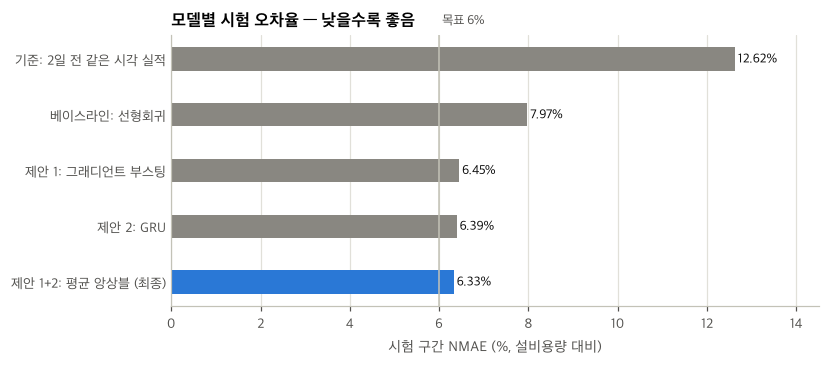

In [16]:
final_row = test_table.loc[FINAL + " ★최종"]
base_row = test_table.loc["베이스라인: 선형회귀"]
ref_row = test_table.loc["기준: 2일 전 같은 시각 실적"]
TARGET = 6.0
goal1 = final_row["묶음 NMAE_이용률10%↑(%)"]
goal2 = final_row["NMAE(%)"]
print(f"최종 모델: {FINAL}")
print(f"목표 1  발전소 묶음 오차율(이용률 10% 이상 시간대) {goal1:.2f}%  → 목표 {TARGET}% {'달성' if goal1 <= TARGET else '미달'}")
print(f"목표 2  개별 발전소 평균 오차율 NMAE {goal2:.2f}%            → 목표 {TARGET}% {'달성' if goal2 <= TARGET else '미달'}")
print(f"베이스라인 대비 NMAE {base_row['NMAE(%)']:.2f}% → {goal2:.2f}% ({(1 - goal2 / base_row['NMAE(%)']):.0%} 감소), 기준 예측 대비 {(1 - goal2 / ref_row['NMAE(%)']):.0%} 감소")

fig, ax = plt.subplots(figsize=(7.6, 3.2))
order = list(test_table.index)[::-1]
colors = [P.BLUE if "★" in k else P.GRAY for k in order]
bars = ax.barh([k.replace(" ★최종", " (최종)") for k in order], test_table.loc[order, "NMAE(%)"], color=colors, height=0.42)
P.bar_labels(ax, bars, "{:.2f}%", horizontal=True)
ax.axvline(TARGET, color=P.AXIS, lw=1)
ax.text(TARGET, len(order) - 0.45, " 목표 6%", fontsize=8.5, color=P.INK2, va="bottom")
ax.set(xlabel="시험 구간 NMAE (%, 설비용량 대비)", title="모델별 시험 오차율 — 낮을수록 좋음", xlim=(0, test_table["NMAE(%)"].max() * 1.15))
ax.grid(True, axis="x"); ax.grid(False, axis="y")
P.save(fig, FIG / "03_test_nmae.png")

### 5-3. 학습 곡선

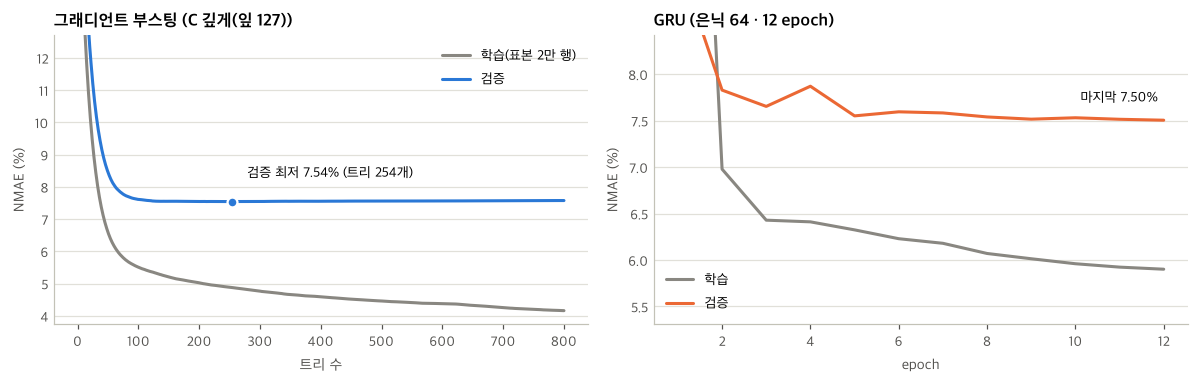

학습-검증 차이: 그래디언트 부스팅 2.67%p · GRU 1.60%p


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
it = np.arange(1, MAX_ITER + 1)
ax.plot(it, g["train"], color=P.GRAY, label="학습(표본 2만 행)")
ax.plot(it, g["val"], color=P.BLUE, label="검증")
ax.scatter([g["best_iter"]], [g["val"].min()], s=42, color=P.BLUE, edgecolor="white", linewidth=1.5, zorder=3)
ax.annotate(f"검증 최저 {g['val'].min():.2f}% (트리 {g['best_iter']}개)", (g["best_iter"], g["val"].min()), xytext=(10, 16), textcoords="offset points", ha="left", fontsize=9)
ax.set(title=f"그래디언트 부스팅 ({best_gbm})", xlabel="트리 수", ylabel="NMAE (%)", ylim=(g["train"].min() * 0.9, g["val"][20] * 1.05))
ax.legend()
ax = axes[1]
h = u["history"]
ax.plot(h["epoch"], h["train_NMAE(%)"], color=P.GRAY, label="학습")
ax.plot(h["epoch"], h["val_NMAE(%)"], color=P.ORANGE, label="검증")
ax.annotate(f"마지막 {h['val_NMAE(%)'].iloc[-1]:.2f}%", (h["epoch"].iloc[-1], h["val_NMAE(%)"].iloc[-1]), xytext=(-4, 12), textcoords="offset points", ha="right", fontsize=9)
ax.set(title=f"GRU ({best_gru})", xlabel="epoch", ylabel="NMAE (%)", ylim=(h["train_NMAE(%)"].min() * 0.9, h["val_NMAE(%)"].iloc[2] * 1.1))
ax.legend()
fig.tight_layout()
P.save(fig, FIG / "04_learning_curves.png")
gap_g = g["val"][g["best_iter"] - 1] - g["train"][g["best_iter"] - 1]
gap_u = h["val_NMAE(%)"].iloc[-1] - h["train_NMAE(%)"].iloc[-1]
print(f"학습-검증 차이: 그래디언트 부스팅 {gap_g:.2f}%p · GRU {gap_u:.2f}%p")

### 5-4. 오류 분석: 언제, 어디서 틀리는가

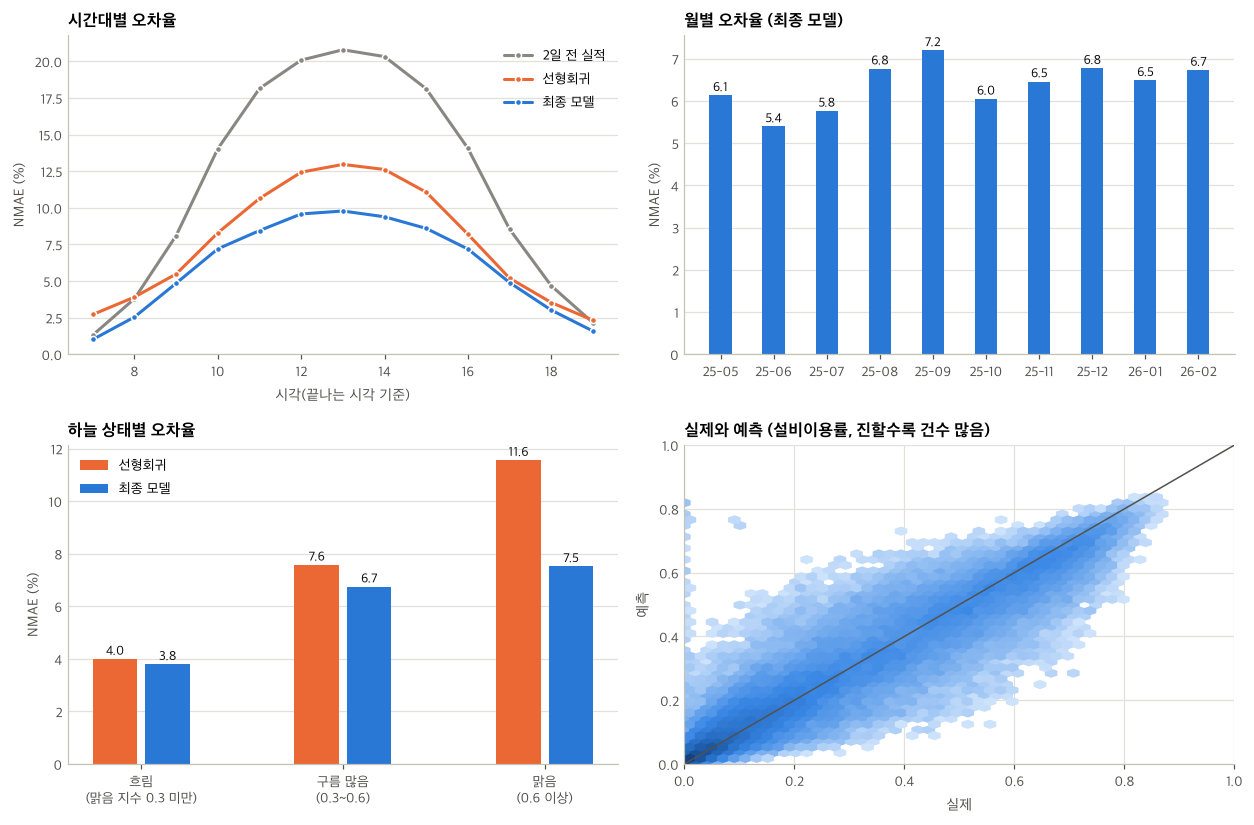

,선형회귀 NMAE(%),최종 모델 NMAE(%),건수
sky,,,
흐림 (맑음 지수 0.3 미만),4.000,3.790,23708
구름 많음 (0.3~0.6),7.580,6.750,51832
맑음 (0.6 이상),11.560,7.520,32044


In [18]:
res = te[["series_id", "name", "region", "date", "hour", "ts_end", "gen_kwh", "capacity_kw", "cf", "kt_mean", "cos_zenith", "ghi_max", "ghi_min", "ghi_mean"]].copy()
res["final"] = pred_te[FINAL_KEY]
res["linear"] = pred_te["선형회귀"]
p2 = M.persistence(df, te, days=2)
res["persist"] = p2
for k in ("final", "linear", "persist"):
    res[f"err_{k}"] = (res[k] - res["gen_kwh"]).abs() / res["capacity_kw"] * 100
res["month"] = res["date"].dt.strftime("%Y-%m")
res["sky"] = pd.cut(res["kt_mean"], [-0.01, 0.3, 0.6, 1.21], labels=["흐림 (맑음 지수 0.3 미만)", "구름 많음 (0.3~0.6)", "맑음 (0.6 이상)"])

fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.6))
ax = axes[0, 0]
by_hour = res.groupby("hour")[["err_persist", "err_linear", "err_final"]].mean()
by_hour = by_hour[res.groupby("hour").size() > 2000]
for col, color, name in (("err_persist", P.GRAY, "2일 전 실적"), ("err_linear", P.ORANGE, "선형회귀"), ("err_final", P.BLUE, "최종 모델")):
    ax.plot(by_hour.index, by_hour[col], color=color, label=name, marker="o", ms=4, markeredgecolor="white")
ax.set(title="시간대별 오차율", xlabel="시각(끝나는 시각 기준)", ylabel="NMAE (%)", ylim=(0, None))
ax.legend()

ax = axes[0, 1]
by_month = res.groupby("month")["err_final"].mean()
bars = ax.bar(by_month.index.str[2:], by_month.values, color=P.BLUE, width=0.42)
P.bar_labels(ax, bars)
ax.set(title="월별 오차율 (최종 모델)", ylabel="NMAE (%)")

ax = axes[1, 0]
by_sky = res.groupby("sky", observed=True)[["err_linear", "err_final"]].mean()
xs = np.arange(len(by_sky))
b1 = ax.bar(xs - 0.13, by_sky["err_linear"], width=0.22, color=P.ORANGE, label="선형회귀")
b2 = ax.bar(xs + 0.13, by_sky["err_final"], width=0.22, color=P.BLUE, label="최종 모델")
P.bar_labels(ax, b1); P.bar_labels(ax, b2)
ax.set_xticks(xs, [s.split(" (")[0] + "\n(" + s.split(" (")[1] for s in by_sky.index])
ax.set(title="하늘 상태별 오차율", ylabel="NMAE (%)")
ax.legend()

ax = axes[1, 1]
hb = ax.hexbin(res["gen_kwh"] / res["capacity_kw"], res["final"] / res["capacity_kw"], gridsize=45, cmap=P.BLUE_CMAP, mincnt=5, bins="log")
ax.plot([0, 1], [0, 1], color=P.INK2, lw=1)
ax.set(title="실제와 예측 (설비이용률, 진할수록 건수 많음)", xlabel="실제", ylabel="예측", xlim=(0, 1), ylim=(0, 1))
ax.grid(True, axis="both")
fig.tight_layout()
P.save(fig, FIG / "05_error_analysis.png")
display(by_sky.rename(columns={"err_linear": "선형회귀 NMAE(%)", "err_final": "최종 모델 NMAE(%)"}).assign(건수=res.groupby("sky", observed=True).size()).round(2))

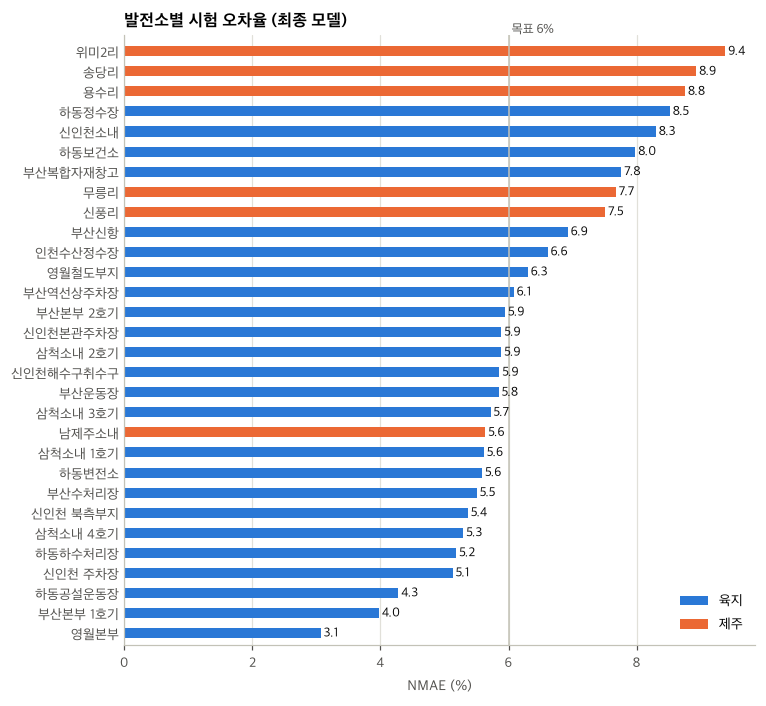

목표 6% 이내 발전소: 17개 / 30개


,평균 NMAE(%),최소,최대,발전소·호기
region,,,,
육지,5.940,3.060,8.520,24
제주,7.980,5.640,9.380,6


,맑은 한낮에 출력이 15% 미만인 시간 비율(%),맑은 한낮 시간 수
region,,
육지,0.780,19129
제주,5.210,3955


In [19]:
# 발전소별 오차율
per_plant = res.groupby(["name", "region"], as_index=False)["err_final"].mean().sort_values("err_final").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.4, 7.2))
for region, color in (("육지", P.BLUE), ("제주", P.ORANGE)):
    s = per_plant[per_plant["region"] == region]
    bars = ax.barh(s.index, s["err_final"], color=color, height=0.5, label=region)
    P.bar_labels(ax, bars, horizontal=True)
ax.set_yticks(per_plant.index, per_plant["name"])
ax.axvline(TARGET, color=P.AXIS, lw=1)
ax.text(TARGET, len(per_plant) - 0.3, " 목표 6%", fontsize=8.5, color=P.INK2, va="bottom")
ax.set(title="발전소별 시험 오차율 (최종 모델)", xlabel="NMAE (%)")
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.legend(loc="lower right")
ax.set_ylim(-0.6, len(per_plant) - 0.2)
P.save(fig, FIG / "06_per_plant.png")
print(f"목표 6% 이내 발전소: {(per_plant['err_final'] <= TARGET).sum()}개 / {len(per_plant)}개")
display(per_plant.groupby("region")["err_final"].agg(["mean", "min", "max", "count"]).round(2).rename(columns={"mean": "평균 NMAE(%)", "min": "최소", "max": "최대", "count": "발전소·호기"}))

# 맑은 한낮인데 출력이 거의 없는 시간: 날씨로 설명되지 않는 감소(출력제어·부분 정지 등)의 흔적
sunny = d2[(d2["split"] == "test") & (d2["kt_mean"] >= 0.6) & (d2["cos_zenith"] >= 0.5)]
low = sunny.assign(low=sunny["y"] < 0.15).groupby("region")["low"].agg(["mean", "size"])
low["mean"] = (low["mean"] * 100).round(2)
display(low.rename(columns={"mean": "맑은 한낮에 출력이 15% 미만인 시간 비율(%)", "size": "맑은 한낮 시간 수"}))

### 5-5. 하루 발전량 등급의 혼동행렬과 오류 사례

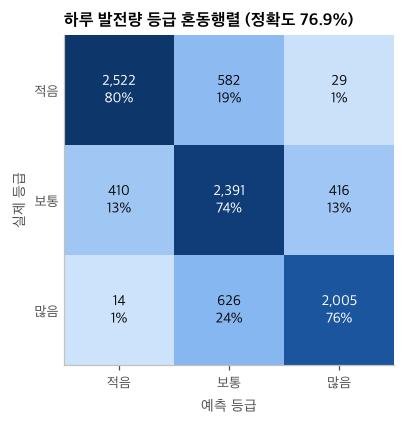

등급 경계(하루 발전량 ÷ 설비용량, 단위 시간): 적음 < 2.38 ≤ 보통 < 4.17 ≤ 많음 · 발전소·일 8,995건


In [20]:
# 하루 발전량(설비용량 대비)을 적음/보통/많음으로 나눠, 예측한 등급이 실제 등급과 맞는지 본다
daily = res.groupby(["series_id", "name", "date"], as_index=False).agg(actual=("gen_kwh", "sum"), pred=("final", "sum"), cap=("capacity_kw", "first"), err=("err_final", "mean"))
daily["a"], daily["p"] = daily["actual"] / daily["cap"], daily["pred"] / daily["cap"]
fit_daily = fit.groupby(["series_id", "date"]).agg(e=("gen_kwh", "sum"), c=("capacity_kw", "first"))
q1, q2 = (fit_daily["e"] / fit_daily["c"]).quantile([1 / 3, 2 / 3])   # 경계는 학습 구간에서 정한다
classes = ["적음", "보통", "많음"]
to_class = lambda s: pd.cut(s, [-1, q1, q2, 99], labels=classes)
cm = pd.crosstab(to_class(daily["a"]), to_class(daily["p"]), rownames=["실제"], colnames=["예측"]).reindex(index=classes, columns=classes, fill_value=0)
acc = np.trace(cm.values) / cm.values.sum()

fig, ax = plt.subplots(figsize=(4.6, 3.9))
ax.imshow(cm.values, cmap=P.BLUE_CMAP)
for i in range(3):
    for j in range(3):
        v = cm.values[i, j]
        ax.text(j, i, f"{v:,}\n{v / cm.values[i].sum():.0%}", ha="center", va="center", fontsize=9.5, color="white" if v > cm.values.max() * 0.5 else P.INK)
ax.set_xticks(range(3), classes); ax.set_yticks(range(3), classes)
ax.set(xlabel="예측 등급", ylabel="실제 등급", title=f"하루 발전량 등급 혼동행렬 (정확도 {acc:.1%})")
ax.grid(False)
P.save(fig, FIG / "07_confusion.png")
print(f"등급 경계(하루 발전량 ÷ 설비용량, 단위 시간): 적음 < {q1:.2f} ≤ 보통 < {q2:.2f} ≤ 많음 · 발전소·일 {len(daily):,}건")

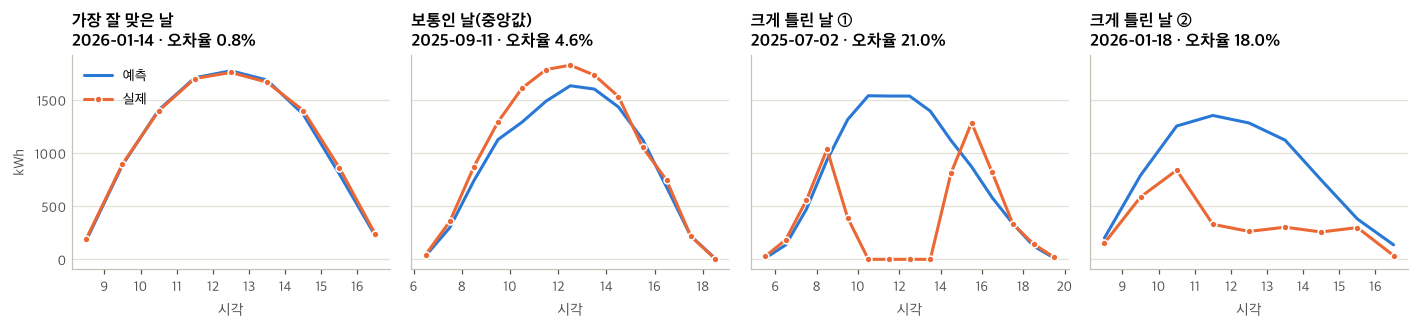

오차율이 가장 컸던 발전소·일 8건


,발전소,날짜,실제(이용률 합),예측(이용률 합),오차율(%),맑음지수,기상 모델 간 예보 차이
0,위미2리,2026-02-17,1.300,5.040,38.150,0.650,0.150
1,부산본부 2호기,2026-02-19,0.840,4.920,37.560,0.670,0.060
2,용수리,2025-05-04,2.160,6.500,37.370,0.670,0.050
3,용수리,2025-09-22,0.210,4.420,37.290,0.520,0.240
4,신풍리,2025-11-06,0.430,4.520,37.220,0.600,0.050
5,위미2리,2026-02-23,1.900,5.500,36.880,0.680,0.040
6,위미2리,2025-05-04,2.160,6.550,36.780,0.680,0.050
7,송당리,2025-05-04,2.220,6.640,35.160,0.690,0.060


In [21]:
# 오류 사례: 삼척소내 4호기(가장 큰 발전소)의 가장 잘 맞은 날, 보통인 날, 가장 크게 틀린 날 둘
one = daily[daily["name"] == "삼척소내 4호기"].sort_values("err").reset_index(drop=True)
picks = [("가장 잘 맞은 날", one.iloc[0]), ("보통인 날(중앙값)", one.iloc[len(one) // 2]), ("크게 틀린 날 ①", one.iloc[-1]), ("크게 틀린 날 ②", one.iloc[-2])]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.1), sharey=True)
for ax, (title, row) in zip(axes, picks):
    x = res[(res["series_id"] == row["series_id"]) & (res["date"] == row["date"])].sort_values("hour")
    ax.plot(x["hour"] - 0.5, x["final"], color=P.BLUE, label="예측")
    ax.plot(x["hour"] - 0.5, x["gen_kwh"], color=P.ORANGE, marker="o", ms=4.5, markeredgecolor="white", label="실제")
    ax.set(title=f"{title}\n{row['date']:%Y-%m-%d} · 오차율 {row['err']:.1f}%", xlabel="시각")
    ax.title.set_fontsize(9.5)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel("kWh")
axes[0].legend(loc="upper left")
fig.tight_layout()
P.save(fig, FIG / "08_cases.png")

extra = res.groupby(["series_id", "date"]).agg(맑음지수=("kt_mean", "mean"), hi=("ghi_max", "sum"), lo=("ghi_min", "sum"), mid=("ghi_mean", "sum")).reset_index()
extra["모델간차이"] = (extra["hi"] - extra["lo"]) / extra["mid"]
worst = daily.sort_values("err", ascending=False).head(8).merge(extra, on=["series_id", "date"])
print("오차율이 가장 컸던 발전소·일 8건")
display(worst[["name", "date", "a", "p", "err", "맑음지수", "모델간차이"]].rename(columns={"name": "발전소", "date": "날짜", "a": "실제(이용률 합)", "p": "예측(이용률 합)", "err": "오차율(%)", "모델간차이": "기상 모델 간 예보 차이"}).round(2))

### 5-6. 기상 모델끼리 예보가 엇갈린 날은 얼마나 더 틀리는가

기상 모델 3종의 일사량 예보가 서로 엇갈리는 정도에 따라 오차가 달라지는지 확인한다. 하루 단위로 `(최대 − 최소) 합 ÷ 평균 합`을 구해 세 구간으로 나누고(경계는 학습 구간의 3분위), 시험 구간에서 구간별 오차율을 잰다. 이 값은 서비스 화면에서 "이런 날의 평균 오차율"로 보여 준다.

In [22]:
def daily_spread(d):
    g = d.groupby(["series_id", "date"])
    return ((g["ghi_max"].sum() - g["ghi_min"].sum()) / g["ghi_mean"].sum()).rename("spread")

cut1, cut2 = daily_spread(fit).quantile([1 / 3, 2 / 3])
sp = daily.merge(daily_spread(te).reset_index(), on=["series_id", "date"])
sp["구간"] = pd.cut(sp["spread"], [-1, cut1, cut2, 99], labels=["작음", "보통", "큼"])
sp = sp.merge(res.groupby(["series_id", "date"])["kt_mean"].mean().rename("kt").reset_index(), on=["series_id", "date"])
spread_table = sp.groupby("구간", observed=True).agg(평균_오차율=("err", "mean"), 평균_맑음지수=("kt", "mean"), 하루_이용률_합=("a", "mean"), 발전소_일=("err", "size"))
display(spread_table.round(2))
print(f"구간 경계: 작음 ≤ {cut1:.2f} < 보통 ≤ {cut2:.2f} < 큼")
print("예보가 가장 크게 엇갈리는 날은 맑음 지수와 발전량이 낮은 흐린 날이라, 설비용량 대비 오차는 '보통' 구간보다 오히려 작다.")
SPREAD_BINS = [
    {"upto": round(float(cut1), 3), "label": "작음", "nmae": round(float(spread_table.loc["작음", "평균_오차율"]), 2)},
    {"upto": round(float(cut2), 3), "label": "보통", "nmae": round(float(spread_table.loc["보통", "평균_오차율"]), 2)},
    {"upto": 99, "label": "큼", "nmae": round(float(spread_table.loc["큼", "평균_오차율"]), 2)},
]

,평균_오차율,평균_맑음지수,하루_이용률_합,발전소_일
구간,,,,
작음,5.740,0.620,3.990,2931
보통,7.010,0.510,3.480,2901
큼,6.390,0.300,2.020,3163


구간 경계: 작음 ≤ 0.13 < 보통 ≤ 0.33 < 큼
예보가 가장 크게 엇갈리는 날은 맑음 지수와 발전량이 낮은 흐린 날이라, 설비용량 대비 오차는 '보통' 구간보다 오히려 작다.


### 5-7. 추가 실험: 기상 모델 수와 예보 시점

같은 부스팅 설정(트리 300개, 학습률 0.1)으로 입력만 바꿔 **검증 구간**에서 비교한다. 예보 시점 비교는 일본 기상청(JMA) 예보의 공통 변수 5개만 쓴다.

In [23]:
lead = []
for site in df["site"].unique():
    w = pd.read_csv(RAW / "weather" / f"{site}_lead.csv.gz")
    lead.append(pd.DataFrame({
        "site": site, "ts_end": pd.to_datetime(w["time"]),
        "ghi_d2": w["shortwave_radiation_previous_day2"], "dir_d2": w["direct_radiation_previous_day2"],
        "dif_d2": w["diffuse_radiation_previous_day2"], "cloud_d2": w["cloud_cover_previous_day2"], "temp_d2": w["temperature_2m_previous_day2"],
    }))
x = d1.merge(pd.concat(lead), on=["site", "ts_end"], how="left")
x["kt_d2"] = (x["ghi_d2"] / x["extra_ghi"].clip(lower=50)).clip(0, 1.2)
GEO = ["cos_zenith", "azimuth", "extra_ghi", "doy_sin", "doy_cos"]
SETS = {
    "JMA 48시간 전 예보 (변수 5개)": ["ghi_d2", "dir_d2", "dif_d2", "cloud_d2", "temp_d2", "kt_d2"] + GEO,
    "JMA 24시간 전 예보 (변수 5개)": ["ghi_jma", "dir_jma", "dif_jma", "cloud_jma", "temp_jma", "kt_jma"] + GEO,
    "JMA 24시간 전 예보 (전체 변수)": [f for f in FEATURES if f.endswith("_jma")] + GEO,
    "기상 모델 3종 24시간 전 예보 (전체 특성)": FEATURES,
}
x = x.dropna(subset=SETS["JMA 48시간 전 예보 (변수 5개)"])
xt, xv = x[x["split"] == "train"], x[x["split"] == "val"]
rows = {}
for name, cols in SETS.items():
    m = HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, learning_rate=0.1, min_samples_leaf=40, random_state=SEED).fit(xt[cols], xt["y"])
    rows[name] = {"특성 수": len(cols), "검증 NMAE(%)": M.evaluate(xv, m.predict(xv[cols]).clip(0) * xv["eff_kw"].to_numpy())["NMAE(%)"]}
ablation = pd.DataFrame(rows).T
display(ablation.round(3))
ablation.round(3).to_csv(ROOT / "docs" / "ablation.csv", encoding="utf-8-sig")

,특성 수,검증 NMAE(%)
JMA 48시간 전 예보 (변수 5개),11.000,9.529
JMA 24시간 전 예보 (변수 5개),11.000,8.437
JMA 24시간 전 예보 (전체 변수),15.000,8.378
기상 모델 3종 24시간 전 예보 (전체 특성),40.000,7.578


## 6. 서비스용 내보내기

최종 모델을 ONNX 파일로 바꿔 `web/model/`에 둔다. 웹 페이지는 이 파일을 내려받아 브라우저 안에서 추론한다(onnxruntime-web).
변환 뒤에는 원래 모델과 예측값이 같은지 시험 자료 전체로 확인한다.

In [24]:
MODEL_DIR = ROOT / "web" / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
Xte = te[FEATURES].to_numpy(np.float32)
models_meta = []

if FINAL_KEY in ("그래디언트 부스팅", "평균 앙상블"):
    onnx_gbm = hgb_to_onnx(gbm2, len(FEATURES)).SerializeToString()
    (MODEL_DIR / "pv_gbm.onnx").write_bytes(onnx_gbm)
    diff = check_parity(gbm2, onnx_gbm, Xte)
    print(f"pv_gbm.onnx  {len(onnx_gbm) / 1024:,.0f} KB · 트리 {gbm2.n_iter_}개 · 시험 {len(Xte):,}행에서 원래 모델과 최대 차이 {diff:.1e}")
    assert diff < 1e-3
    models_meta.append({"name": "그래디언트 부스팅", "file": "pv_gbm.onnx", "kind": "tabular", "weight": 1.0})

if FINAL_KEY in ("GRU", "평균 앙상블"):
    import onnxruntime as ort
    gru2.eval()
    torch.onnx.export(
        gru2, torch.zeros(1, M.HOURS, len(FEATURES)), str(MODEL_DIR / "pv_gru.onnx"),
        input_names=["features"], output_names=["prediction"],
        dynamic_axes={"features": {0: "batch"}, "prediction": {0: "batch"}}, opset_version=17, dynamo=False,
    )
    day_te = M.DayData(te, FEATURES, mean2, std2)
    sess = ort.InferenceSession(str(MODEL_DIR / "pv_gru.onnx"), providers=["CPUExecutionProvider"])
    got = sess.run(None, {"features": day_te.x.numpy()})[0]
    diff = float(np.abs(np.clip(got, 0, None) - M.predict_gru(gru2, day_te)).max())
    print(f"pv_gru.onnx  {(MODEL_DIR / 'pv_gru.onnx').stat().st_size / 1024:,.0f} KB · 파라미터 {sum(p.numel() for p in gru2.parameters()):,}개 · 시험 {len(day_te):,}일에서 원래 모델과 최대 차이 {diff:.1e}")
    assert diff < 1e-3
    models_meta.append({"name": "GRU", "file": "pv_gru.onnx", "kind": "sequence", "weight": 1.0, "mean": [float(v) for v in mean2], "std": [float(v) for v in std2]})

assert models_meta, "선형회귀가 최종 모델로 뽑히면 내보내기 코드를 추가해야 한다"
for stale in MODEL_DIR.glob("*.onnx"):          # 이번에 쓰지 않는 예전 모델 파일만 지운다
    if stale.name not in {m["file"] for m in models_meta}:
        stale.unlink()

pv_gbm.onnx  2,103 KB · 트리 254개 · 시험 107,584행에서 원래 모델과 최대 차이 2.3e-07


pv_gru.onnx  533 KB · 파라미터 135,361개 · 시험 8,995일에서 원래 모델과 최대 차이 3.0e-07


In [25]:
# 서비스 화면이 쓰는 정보(meta.json)와 '지난 날짜로 확인'용 실제 발전량
DEMO = ["samcheok_4", "busan_field", "sinincheon_park", "yeongwol_rail", "hadong_stadium", "incheon_susan", "wimi2", "namjeju", "hwachon", "icheon_a", "hadong_main_2", "wasan"]
all_res = pd.concat([
    te.assign(pred=pred_te[FINAL_KEY]), tn.assign(pred=pred_tn[FINAL_KEY]),
])
all_res["err"] = (all_res["pred"] - all_res["gen_kwh"]).abs() / all_res["capacity_kw"] * 100
plant_nmae = all_res.groupby("series_id")["err"].mean()
info = d2.drop_duplicates("series_id").set_index("series_id")
area = used.set_index("series_id")["area"]
plants_meta = [
    {
        "id": sid, "name": info.loc[sid, "name"], "area": area[sid], "lat": float(info.loc[sid, "lat"]), "lon": float(info.loc[sid, "lon"]),
        "capacity_kw": float(info.loc[sid, "capacity_kw"]),
        "eff_kw": None if bool(info.loc[sid, "new_site"]) else round(float(eff2[sid]), 2),
        "new_site": bool(info.loc[sid, "new_site"]), "nmae": round(float(plant_nmae[sid]), 2),
    }
    for sid in DEMO
]

def metric_row(name, kind, row, final=False):
    return {"name": name, "kind": kind, "final": final, "nmae": round(float(row["NMAE(%)"]), 3), "rmse": round(float(row["RMSE(%)"]), 3),
            "r2": round(float(row["R2"]), 4), "portfolio_nmae": round(float(row["묶음 NMAE(%)"]), 3)}

kinds = {"기준": "기준(학습 없음)", "베이스라인": "베이스라인", "제안 1": "제안 모델", "제안 2": "제안 모델", "제안 1+2": "제안 모델"}
meta = {
    "title": "내일 태양광 발전량 예측기",
    "exported_at": pd.Timestamp.now(tz="Asia/Seoul").strftime("%Y-%m-%d %H:%M"),
    "final_model": FINAL,
    "features": FEATURES,
    "models": models_meta,
    "default_ratio": round(ratio2, 4),
    "y_max": 1.3,
    "target": TARGET,
    "periods": {"train": [report["split_days"]["train"][0], report["split_days"]["train"][1]], "val": report["split_days"]["val"], "test": report["split_days"]["test"]},
    "data": {"series": int(te["series_id"].nunique()), "sites": int(te["site"].nunique()), "fit_rows": int(len(fit)), "test_rows": int(len(te)), "new_site_series": int(tn["series_id"].nunique())},
    "metrics": [metric_row(k.split(": ")[1].replace(" ★최종", ""), kinds[k.split(":")[0]], v, "★" in k) for k, v in test_table.iterrows()],
    "goal": {"portfolio_nmae_active": round(float(goal1), 3), "plant_nmae": round(float(goal2), 3)},
    "spread_bins": SPREAD_BINS,
    "plants": plants_meta,
}
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")

# 실제 발전량(시험 구간, 24시간 전체). 정지일로 제외된 날은 넣지 않는다.
gen_all = before[before["series_id"].isin(DEMO) & (before["date"] >= report["split_days"]["test"][0])]
valid_days = set(zip(all_res["series_id"], all_res["date"]))
actuals = {}
for (sid, date), part in gen_all.groupby(["series_id", "date"]):
    if (sid, date) in valid_days:
        actuals.setdefault(sid, {})[date.strftime("%Y-%m-%d")] = [round(float(v), 2) for v in part.sort_values("hour")["gen_kwh"]]
(ROOT / "web" / "data").mkdir(exist_ok=True)
(ROOT / "web" / "data" / "actuals.json").write_text(json.dumps(actuals, separators=(",", ":")), encoding="utf-8")

# 파이썬과 웹(자바스크립트) 계산이 같은지 확인하기 위한 표본: 원자료 날씨 → 특성 → 예측
samples = []
for sid, date in [("samcheok_4", "2025-07-15"), ("wimi2", "2025-12-20"), ("hwachon", "2025-10-03"), ("busan_field", "2026-02-10")]:
    rows = all_res[(all_res["series_id"] == sid) & (all_res["date"] == date)].sort_values("hour")
    if rows.empty:   # 정지일로 빠진 날이면 건너뛴다
        continue
    w = pd.read_csv(RAW / "weather" / f"{rows['site'].iloc[0]}_d1.csv.gz")
    i0 = w.index[w["time"] == f"{date}T01:00"][0]
    weather = {}
    for model, short in build_dataset.SHORT.items():
        for var, vshort in build_dataset.WVARS.items():
            col = f"{var}_previous_day1_{model}"
            vals = w[col].iloc[i0 : i0 + 24].tolist() if col in w else [None] * 24
            weather[f"{vshort}_{short}"] = [None if pd.isna(v) else float(v) for v in vals]
    p = next(x for x in plants_meta if x["id"] == sid)
    samples.append({
        "plant": p, "date": date, "weather": weather, "hours": rows["hour"].tolist(),
        "features": rows[FEATURES].to_numpy(float).round(5).tolist(), "pred_kwh": rows["pred"].round(4).tolist(),
    })
(ROOT / "tests").mkdir(exist_ok=True)
(ROOT / "tests" / "parity_samples.json").write_text(json.dumps({"samples": samples}), encoding="utf-8")

for path in sorted(MODEL_DIR.iterdir()) + [ROOT / "web" / "data" / "actuals.json", ROOT / "tests" / "parity_samples.json"]:
    print(f"{path.relative_to(ROOT)!s:<32} {path.stat().st_size / 1024:>8,.0f} KB")

web/model/meta.json                     7 KB
web/model/pv_gbm.onnx               2,103 KB
web/model/pv_gru.onnx                 533 KB
web/data/actuals.json                 490 KB
tests/parity_samples.json              31 KB


## 7. 요약

In [26]:
print(f"데이터   발전소·호기 {df['series_id'].nunique()}개(위치 {df['site'].nunique()}곳) · 낮 시간 {len(df):,}행 · 특성 {len(FEATURES)}개")
print(f"최종 모델 {FINAL}")
print(f"시험 성능 개별 발전소 NMAE {goal2:.2f}% (선형회귀 {base_row['NMAE(%)']:.2f}%, 2일 전 실적 {ref_row['NMAE(%)']:.2f}%) · R² {final_row['R2']:.3f}")
print(f"         발전소 묶음 오차율 {final_row['묶음 NMAE(%)']:.2f}% (이용률 10% 이상 시간대 {goal1:.2f}%)")
print(f"         처음 보는 발전소 NMAE {new_table.loc[FINAL + ' ★최종', 'NMAE(%)']:.2f}%")
print(f"목표     묶음 6% 이하: {'달성' if goal1 <= TARGET else '미달'} · 개별 발전소 6% 이하: {'달성' if goal2 <= TARGET else '미달'}")

데이터   발전소·호기 40개(위치 18곳) · 낮 시간 343,306행 · 특성 40개
최종 모델 제안 1+2: 평균 앙상블
시험 성능 개별 발전소 NMAE 6.33% (선형회귀 7.97%, 2일 전 실적 12.62%) · R² 0.819
         발전소 묶음 오차율 2.93% (이용률 10% 이상 시간대 3.82%)
         처음 보는 발전소 NMAE 8.49%
목표     묶음 6% 이하: 달성 · 개별 발전소 6% 이하: 미달
